# Nucleotide heatmap

Run all cells with the `silscore` environment; the included caches are sufficient.

Generated from [nb5_nucleotide_heatmap.py](nb5_nucleotide_heatmap.py).

In [1]:
"""Cached nucleotide preferences for the main paper and supplement.

Read the aggregate NPZ cache.
"""
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.ticker import FuncFormatter
from IPython.display import Image, display
import numpy as np


def _resolve_root() -> Path:
    file_name = globals().get("__file__")
    if file_name:
        return Path(file_name).resolve().parents[1]
    cwd = Path.cwd().resolve()
    if (cwd / "data" / "cache").is_dir():
        return cwd
    if cwd.name == "notebooks" and (cwd.parent / "data" / "cache").is_dir():
        return cwd.parent
    raise RuntimeError("cannot resolve Silscore root from __file__ or cwd")


ROOT = _resolve_root()
CACHE = ROOT / "data" / "cache" / "nucleotide_heatmap.npz"
OUT = ROOT / "output" / "figures"
BASES = ("U", "A", "C", "G")
DATASETS = ("huesken", "mix", "taka")
FIG_W = 5.586
FS_TICK, FS_LABEL, FS_TITLE = 8.0, 9.0, 8.0
MAP_LEFT, MAP_WIDTH = 0.43, 4.20
MAP_HEIGHT = MAP_WIDTH * len(BASES) / 19
COLORBAR_LEFT, COLORBAR_WIDTH = 4.76, 0.07
COLORBAR_TICKS = (-0.10, -0.05, 0.0, 0.05, 0.10)
PAPER_STYLE = {"font.family": "DejaVu Sans", "font.size": FS_TICK,
               "axes.linewidth": 0.6, "pdf.fonttype": 42, "ps.fonttype": 42}


def read_cache() -> dict[str, np.ndarray | float | str]:
    """Read and check the aggregate arrays needed by the two figures."""
    if not CACHE.exists():
        raise FileNotFoundError(f"missing {CACHE}")
    with np.load(CACHE, allow_pickle=False) as archive:
        required = {
            "datasets", "bases", "positions", "n_guides", "mean_scores",
            "column_means", "centered_scores", "stddev", "sd_ddof",
            "model_sha256", "input_sha256",
        }
        missing = sorted(required.difference(archive.files))
        if missing:
            raise ValueError(f"nucleotide heatmap cache is missing arrays: {missing}")
        data = {name: archive[name].copy() for name in required}

    if tuple(data["datasets"].astype(str)) != DATASETS:
        raise ValueError("unexpected dataset order in nucleotide heatmap cache")
    if tuple(data["bases"].astype(str)) != BASES:
        raise ValueError("unexpected base order in nucleotide heatmap cache")
    if not np.array_equal(data["positions"], np.arange(1, 20)):
        raise ValueError("unexpected guide positions in nucleotide heatmap cache")
    expected_shapes = {
        "n_guides": (3,), "mean_scores": (3, 4, 19),
        "column_means": (3, 19), "centered_scores": (3, 4, 19),
        "stddev": (4, 19), "input_sha256": (3,),
    }
    for name, shape in expected_shapes.items():
        if data[name].shape != shape:
            raise ValueError(f"{name} has shape {data[name].shape}; expected {shape}")
    if not np.array_equal(data["n_guides"], np.array([249, 472, 702])):
        raise ValueError("unexpected guide counts in nucleotide heatmap cache")
    if np.asarray(data["sd_ddof"]).shape != () or int(data["sd_ddof"]) != 0:
        raise ValueError("expected descriptive SD with ddof=0")
    return data


def shared_norm(data: dict[str, np.ndarray | float | str]) -> Normalize:
    """Use the full three-dataset range for both the main and SI figures."""
    vmax = float(np.max(np.abs(data["centered_scores"])))
    return Normalize(vmin=-vmax, vmax=vmax)


def map_axes(fig, bottom: float, matrix: np.ndarray, title: str,
             norm: Normalize, *, xlabel: bool = True):
    """Draw a vector heatmap with square cells and paper-sized typography."""
    height = fig.get_figheight()
    ax = fig.add_axes([MAP_LEFT / FIG_W, bottom / height,
                       MAP_WIDTH / FIG_W, MAP_HEIGHT / height])
    mesh = ax.pcolormesh(np.arange(0.5, 20.0), np.arange(-0.5, 4.0), matrix,
                         cmap="RdBu_r", norm=norm, shading="flat",
                         edgecolors="white", linewidth=0.35, antialiased=False)
    ax.set_xlim(0.5, 19.5)
    ax.set_ylim(3.5, -0.5)
    ax.set_aspect("equal")
    ax.set_xticks(np.arange(1, 20))
    ax.set_yticks(np.arange(4), BASES)
    ax.tick_params(labelsize=FS_TICK, length=2.5, width=0.6, pad=3)
    ax.tick_params(axis="x", labelbottom=xlabel)
    if xlabel:
        ax.set_xlabel("guide position (5′→3′)", fontsize=FS_LABEL, labelpad=4)
    ax.set_title(title, loc="left", fontsize=FS_TITLE, pad=5)
    for spine in ax.spines.values():
        spine.set_visible(False)
    return mesh


def add_colorbar(fig, mesh, bottom: float, height: float) -> None:
    fig_height = fig.get_figheight()
    cax = fig.add_axes([COLORBAR_LEFT / FIG_W, bottom / fig_height,
                        COLORBAR_WIDTH / FIG_W, height / fig_height])
    colorbar = fig.colorbar(mesh, cax=cax, ticks=COLORBAR_TICKS)
    if colorbar.solids is not None:
        colorbar.solids.set_rasterized(False)
        colorbar.solids.set_edgecolor("face")
    colorbar.ax.yaxis.set_major_formatter(
        FuncFormatter(lambda value, _: "0" if value == 0 else f"{value:.2f}"))
    colorbar.ax.tick_params(labelsize=FS_TICK, length=2.5, width=0.6, pad=3)
    colorbar.set_label("Score deviation\nfrom four-base mean", fontsize=FS_LABEL, labelpad=5)
    colorbar.outline.set_linewidth(0.6)


def export_and_display(fig, stem: str) -> None:
    OUT.mkdir(parents=True, exist_ok=True)
    for extension in ("png", "pdf"):
        # Preserve the physical width and vector cells and text.
        fig.savefig(OUT / f"{stem}.{extension}", facecolor="white", dpi=300)
    plt.close(fig)
    display(Image(filename=str(OUT / f"{stem}.png")))


def plot_main(data: dict[str, np.ndarray | float | str]) -> None:
    """Export the Huesken test map for the main paper."""
    with plt.rc_context(PAPER_STYLE):
        fig = plt.figure(figsize=(FIG_W, 1.75), dpi=300)
        mesh = map_axes(fig, 0.48, np.asarray(data["centered_scores"])[0],
                        "Nucleotide preference", shared_norm(data))
        add_colorbar(fig, mesh, 0.48, MAP_HEIGHT)
        export_and_display(fig, "fig_nucleotide_heatmap")


def plot_supplement(data: dict[str, np.ndarray | float | str]) -> None:
    """Export Mixset and Katoh-Suzuki on the same scale as Huesken."""
    values = np.asarray(data["centered_scores"])
    norm = shared_norm(data)
    with plt.rc_context(PAPER_STYLE):
        fig = plt.figure(figsize=(FIG_W, 3.10), dpi=300)
        map_axes(fig, 1.74, values[1], "A  Mixset", norm, xlabel=False)
        mesh = map_axes(fig, 0.48, values[2], "B  Katoh–Suzuki", norm)
        add_colorbar(fig, mesh, 0.48, 1.74 + MAP_HEIGHT - 0.48)
        export_and_display(fig, "fig_nucleotide_heatmap_supplement")

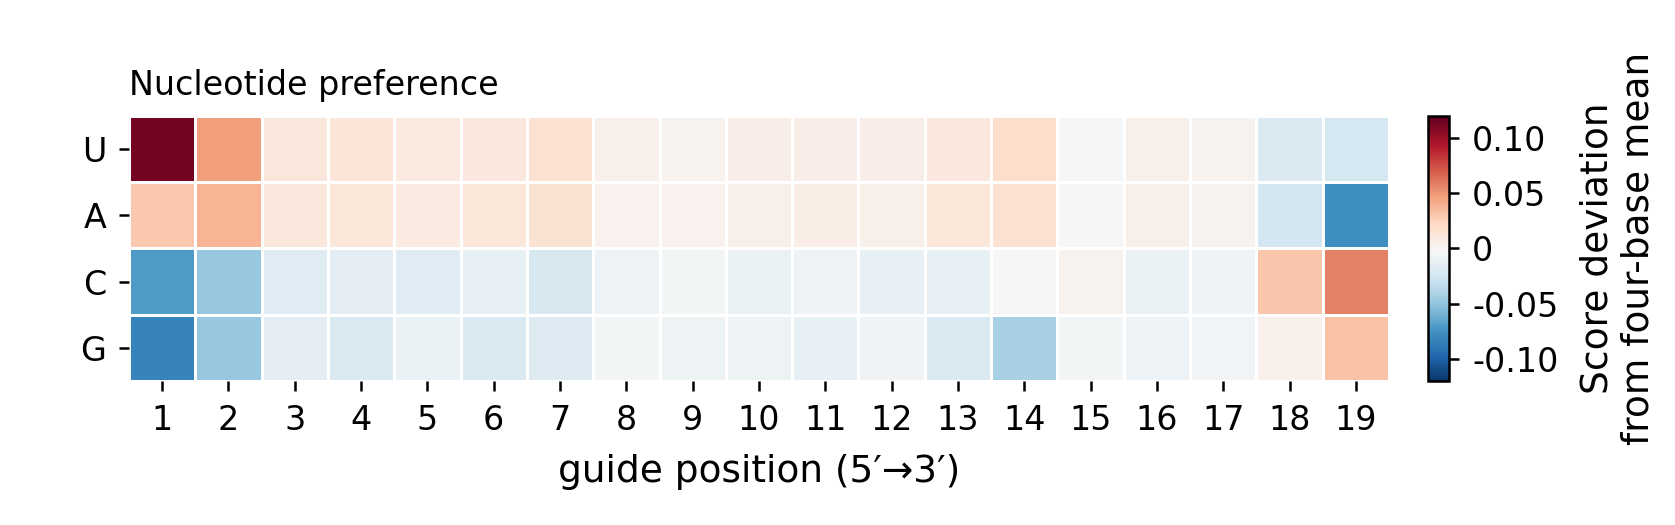

In [2]:
data = read_cache()
plot_main(data)

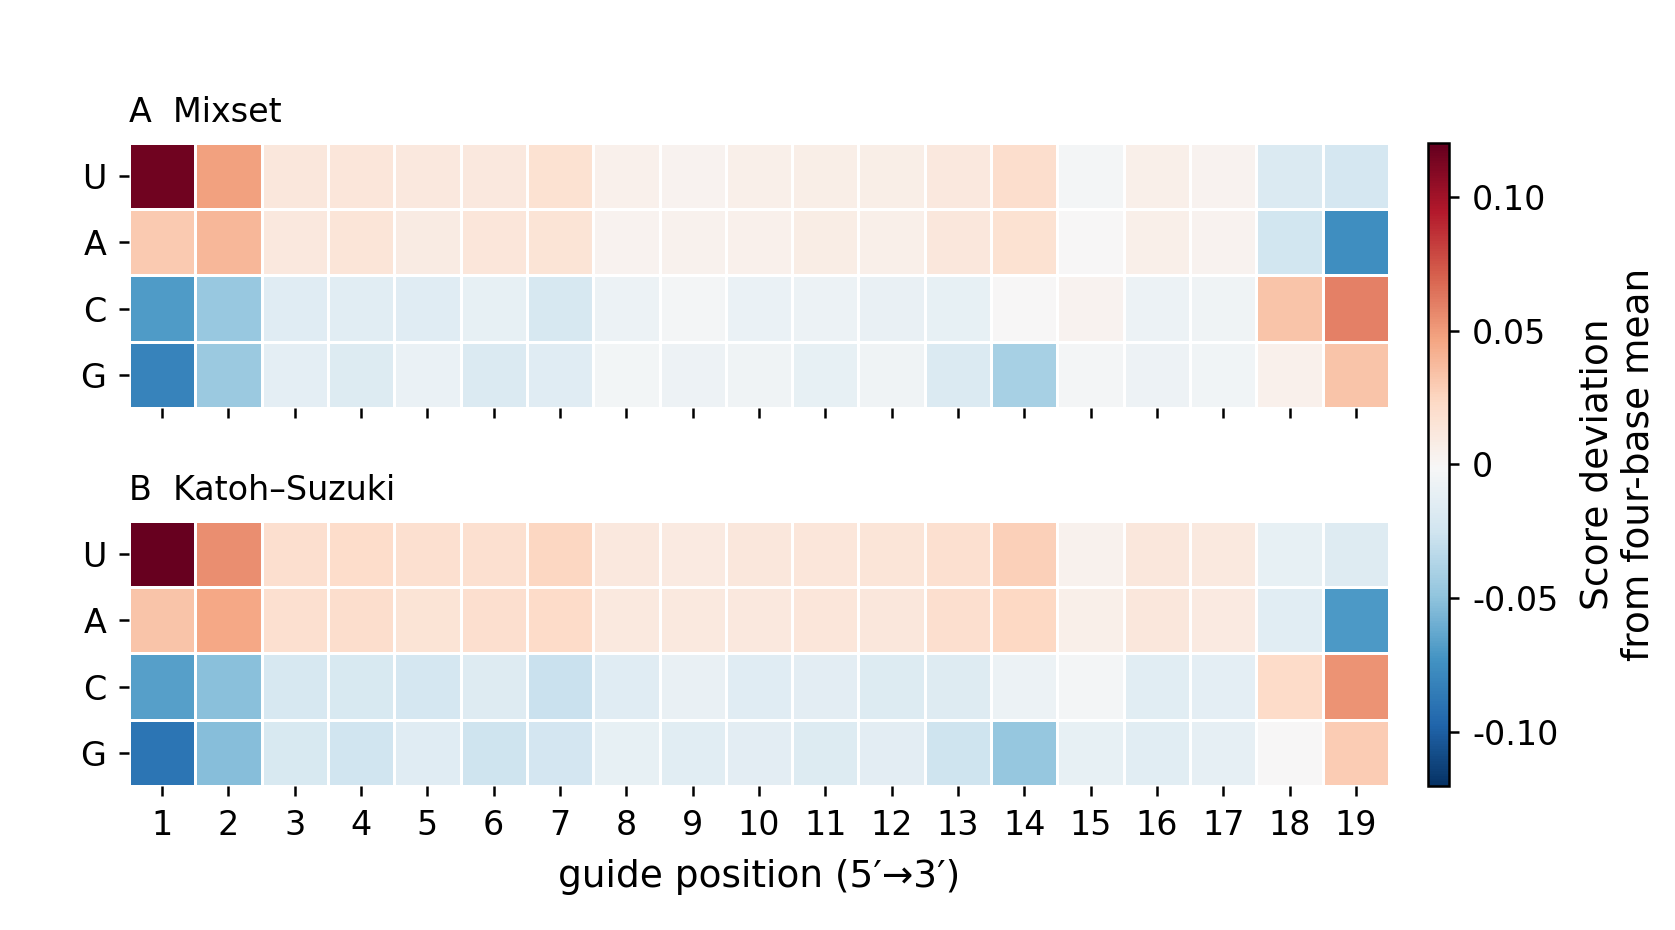

In [3]:
plot_supplement(data)